## 1. Import Libraries
PyTorch is used to build and train the CNN, Hugging Face `datasets` to load the data, `torchinfo` for the model summary, and scikit-learn / matplotlib for evaluation and plots.

In [9]:
%pip -q install datasets torchinfo

import random
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from datasets import load_dataset
from torchinfo import summary
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# Fixed seed so results are reproducible
random.seed(42); np.random.seed(42); torch.manual_seed(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: cuda


## 2. Load and Explore Dataset
**Dataset description:** The Beans dataset contains photos of bean plant leaves taken in the field in Uganda. Each image belongs to one of **3 classes**:
- `angular_leaf_spot` - leaf disease (spots on the leaf)
- `bean_rust` - leaf disease (rust-coloured pustules)
- `healthy` - healthy leaf

It comes with an official train / validation / test split, so we use it as given.

Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
train      total=1034  per class={'angular_leaf_spot': np.int64(345), 'bean_rust': np.int64(348), 'healthy': np.int64(341)}
validation total=133  per class={'angular_leaf_spot': np.int64(44), 'bean_rust': np.int64(45), 'healthy': np.int64(44)}
test       total=128  per class={'angular_leaf_spot': np.int64(43), 'bean_rust': np.int64(43), 'healthy': np.int64(42)}
Image size (first image): (500, 500)


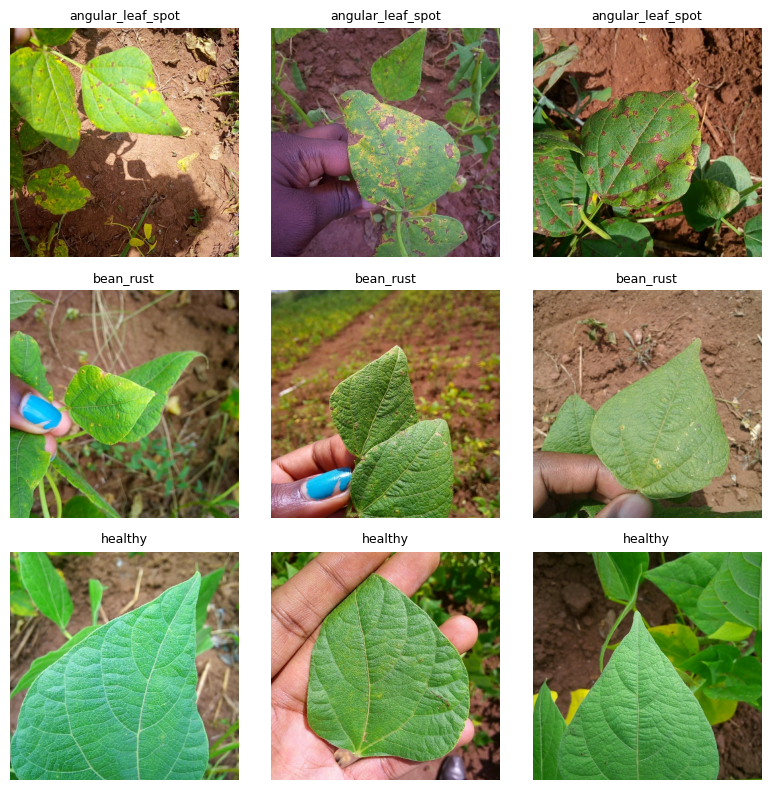

In [10]:
data = load_dataset('AI-Lab-Makerere/beans')
classes = data['train'].features['labels'].names
print('Classes:', classes)

# Split sizes and number of images per class
for split in ['train', 'validation', 'test']:
    counts = np.bincount(data[split]['labels'], minlength=len(classes))
    print(f'{split:10s} total={len(data[split])}  per class={dict(zip(classes, counts))}')

print('Image size (first image):', data['train'][0]['image'].size)

# Show 3 sample images per class
fig, axes = plt.subplots(len(classes), 3, figsize=(8, 8))
for c in range(len(classes)):
    idx = [i for i, l in enumerate(data['train']['labels']) if l == c][:3]
    for j, i in enumerate(idx):
        axes[c, j].imshow(data['train'][i]['image']); axes[c, j].axis('off')
        axes[c, j].set_title(classes[c], fontsize=9)
plt.tight_layout(); plt.show()

## 3. Data Preprocessing & Augmentation
- **Resize to 128 x 128** - original images are large; a smaller fixed size makes training fast and keeps every input the same shape.
- **Normalize** to the range [-1, 1] - helps the network train more stably.
- **Augmentation (training only):** random horizontal flip and small random rotation - leaves can appear in any orientation, and this reduces overfitting. Validation and test images are **not** augmented.
- **Batch size 32** for the training, validation and test loaders. Only the training loader is shuffled.

In [11]:
train_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])
eval_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

class BeansDataset(Dataset):
    def __init__(self, split, transform):
        self.split, self.transform = split, transform
    def __len__(self):
        return len(self.split)
    def __getitem__(self, i):
        item = self.split[i]
        return self.transform(item['image'].convert('RGB')), item['labels']

BATCH_SIZE = 32
train_loader = DataLoader(BeansDataset(data['train'], train_tf), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(BeansDataset(data['validation'], eval_tf), batch_size=BATCH_SIZE)
test_loader  = DataLoader(BeansDataset(data['test'], eval_tf), batch_size=BATCH_SIZE)
print('Batches -> train:', len(train_loader), '| val:', len(val_loader), '| test:', len(test_loader))

Batches -> train: 33 | val: 5 | test: 4


## 4. Define CNN Architecture
A custom CNN built from scratch (no pretrained weights) with **4 convolution blocks**. Each block is `Conv -> BatchNorm -> ReLU -> MaxPool`.

**Design justification:**
- **Conv layers (3x3 kernels, filters 32 -> 64 -> 128 -> 256):** early layers learn simple features (edges, colour), deeper layers learn complex ones (leaf spots, rust patterns). Doubling the filters while pooling halves the image size is a standard design.
- **BatchNorm:** stabilises and speeds up training.
- **ReLU:** helps reduce vanishing-gradient problems.
- **MaxPool (2x2):** reduces the image size and keeps the strongest features.
- **Global average pooling:** replaces a large flatten layer, so there are far fewer parameters and less overfitting.
- **Dropout (0.3):** randomly drops neurons during training to reduce overfitting.
- **Final Linear layer (3 outputs):** one score per class.

In [12]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        def block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(),
                nn.MaxPool2d(2)
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Dropout(0.3), nn.Linear(256, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = CustomCNN(len(classes)).to(device)
summary(model, input_size=(1, 3, 128, 128),
        col_names=['input_size', 'output_size', 'num_params'])

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
CustomCNN                                [1, 3, 128, 128]          [1, 3]                    --
├─Sequential: 1-1                        [1, 3, 128, 128]          [1, 256, 8, 8]            --
│    └─Sequential: 2-1                   [1, 3, 128, 128]          [1, 32, 64, 64]           --
│    │    └─Conv2d: 3-1                  [1, 3, 128, 128]          [1, 32, 128, 128]         896
│    │    └─BatchNorm2d: 3-2             [1, 32, 128, 128]         [1, 32, 128, 128]         64
│    │    └─ReLU: 3-3                    [1, 32, 128, 128]         [1, 32, 128, 128]         --
│    │    └─MaxPool2d: 3-4               [1, 32, 128, 128]         [1, 32, 64, 64]           --
│    └─Sequential: 2-2                   [1, 32, 64, 64]           [1, 64, 32, 32]           --
│    │    └─Conv2d: 3-5                  [1, 32, 64, 64]           [1, 64, 64, 64]           18,496
│    │    └─BatchNorm2d: 3-6  

## 5. Training Loop with Validation
**Hyperparameters and rationale:**

| Hyperparameter | Value | Why |
|---|---|---|
| Loss | CrossEntropyLoss | standard loss for multi-class classification (3 classes) |
| Optimizer | Adam | adapts the learning rate per weight, converges fast with little tuning |
| Learning rate | 0.001 | common, safe starting value for Adam |
| Batch size | 32 | good balance between speed, memory and stable gradients |
| Epochs | 25 | 25 epochs provide sufficient training opportunities while keeping computational cost manageable. |
| Dropout | 0.3 | reduces overfitting |

The model with the **best validation accuracy** is kept and used for testing.

In [13]:
EPOCHS = 25
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Run one epoch of training (training=True) or evaluation (training=False)
def run_epoch(loader, training=False):
    model.train(training)
    total_loss = correct = total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

train_loss, val_loss, train_acc, val_acc = [], [], [], []
best_val_acc = 0
for epoch in range(EPOCHS):
    tl, ta = run_epoch(train_loader, training=True)
    vl, va = run_epoch(val_loader)
    train_loss.append(tl); train_acc.append(ta)
    val_loss.append(vl);   val_acc.append(va)
    if va > best_val_acc:                       # keep the best model
        best_val_acc = va
        torch.save(model.state_dict(), 'CNN_StudetID.pth')
    print(f'Epoch {epoch+1}/{EPOCHS}: train loss={tl:.3f}, acc={ta:.2%} | val loss={vl:.3f}, acc={va:.2%}')
print(f'Best validation accuracy: {best_val_acc:.2%}')

Epoch 1/25: train loss=0.809, acc=65.57% | val loss=1.204, acc=35.34%
Epoch 2/25: train loss=0.694, acc=70.50% | val loss=0.706, acc=67.67%
Epoch 3/25: train loss=0.661, acc=71.47% | val loss=0.735, acc=65.41%
Epoch 4/25: train loss=0.626, acc=73.60% | val loss=0.560, acc=76.69%
Epoch 5/25: train loss=0.607, acc=76.02% | val loss=0.578, acc=75.94%
Epoch 6/25: train loss=0.592, acc=76.50% | val loss=0.478, acc=78.95%
Epoch 7/25: train loss=0.562, acc=77.37% | val loss=0.440, acc=82.71%
Epoch 8/25: train loss=0.529, acc=78.43% | val loss=0.408, acc=84.21%
Epoch 9/25: train loss=0.497, acc=80.85% | val loss=0.792, acc=67.67%
Epoch 10/25: train loss=0.554, acc=77.56% | val loss=0.418, acc=82.71%
Epoch 11/25: train loss=0.478, acc=80.56% | val loss=0.448, acc=83.46%
Epoch 12/25: train loss=0.476, acc=80.95% | val loss=0.563, acc=78.20%
Epoch 13/25: train loss=0.440, acc=83.46% | val loss=0.406, acc=83.46%
Epoch 14/25: train loss=0.464, acc=81.53% | val loss=0.367, acc=84.21%
Epoch 15/25: tr

## 6. Evaluate Model on Test Set
Load the best saved weights and evaluate once on the unseen test set. Report loss, accuracy, precision, recall and F1-score. The weights are saved in `CNN_StudetID.pth`.

In [14]:
# Load best weights (saved during training)
model.load_state_dict(torch.load('CNN_StudetID.pth', map_location=device))

test_loss, test_accuracy = run_epoch(test_loader)
true_labels, predictions = [], []
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        true_labels.extend(labels.tolist())
        predictions.extend(outputs.argmax(1).cpu().tolist())

print(f'Test loss: {test_loss:.4f} | Test accuracy: {test_accuracy:.2%}\n')
print(classification_report(true_labels, predictions, target_names=classes, zero_division=0))
print('Model weights saved at: CNN_StudetID.pth')

Test loss: 0.3006 | Test accuracy: 89.06%

                   precision    recall  f1-score   support

angular_leaf_spot       0.87      0.91      0.89        43
        bean_rust       0.88      0.81      0.84        43
          healthy       0.93      0.95      0.94        42

         accuracy                           0.89       128
        macro avg       0.89      0.89      0.89       128
     weighted avg       0.89      0.89      0.89       128

Model weights saved at: CNN_StudetID.pth


## 7. Visualizations (Loss/Accuracy Curves)
Training and validation loss and accuracy for every epoch.

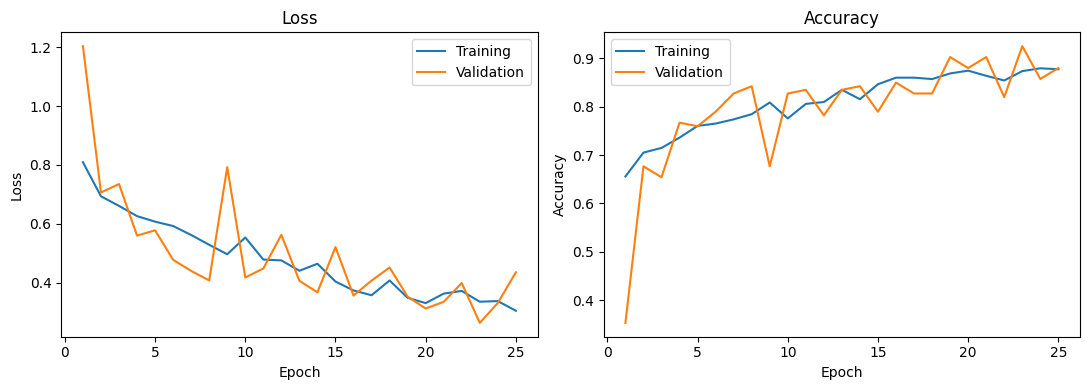

In [15]:
epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_loss, label='Training')
plt.plot(epochs_range, val_loss, label='Validation')
plt.title('Loss'); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_acc, label='Training')
plt.plot(epochs_range, val_acc, label='Validation')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.tight_layout(); plt.show()

**How to read the curves:**
- Loss going **down** and accuracy going **up** for both training and validation means the model is learning.
- If training accuracy keeps rising but validation accuracy stops or drops, the model is **overfitting**.
- If both stay low, the model is **underfitting** (too simple or trained too little).
- Validation curves are a bit noisy because the validation set is small (133 images).

## 8. Analysis & Discussion of Results

In [16]:
print(f'Final training accuracy  : {train_acc[-1]:.2%}')
print(f'Final validation accuracy: {val_acc[-1]:.2%}')
print(f'Best validation accuracy : {best_val_acc:.2%}')
print(f'Test accuracy            : {test_accuracy:.2%}')

gap = (train_acc[-1] - val_acc[-1]) * 100
print(f'\nTraining - validation accuracy gap: {gap:.1f} percentage points')
if gap > 10:
    print('Large gap -> the model is overfitting.')
elif train_acc[-1] < 0.75:
    print('Both accuracies are low -> the model is underfitting.')
else:
    print('Small gap and good accuracy -> the model generalizes well.')

Final training accuracy  : 87.72%
Final validation accuracy: 87.97%
Best validation accuracy : 92.48%
Test accuracy            : 89.06%

Training - validation accuracy gap: -0.3 percentage points
Small gap and good accuracy -> the model generalizes well.


- The **test accuracy** is measured on images the model never saw, so it is the fairest measure of real performance.
- The **classification report** (Section 6) shows that bean rust has the lowest recall (0.81), compared with angular leaf spot (0.91) and healthy leaves (0.95). This indicates that the model misses more actual bean rust cases.
- Batch normalization, dropout and data augmentation were used to improve learning and reduce overfitting.

## 9. Conclusions & Future Work
**Conclusion:** A custom 4-block CNN was trained from scratch on the Beans dataset to classify bean leaves as angular leaf spot, bean rust or healthy. It was trained with Adam and cross-entropy loss, the best model (by validation accuracy) was evaluated on the test set, and the weights were saved to `CNN_StudetID.pth`.

**Future work:**
- Train for more epochs and add a learning-rate scheduler.
- Use stronger augmentation (colour jitter, vertical flip, random crop).
- Try a larger input size or a deeper network.
- Use transfer learning (e.g. ResNet18 pretrained on ImageNet) for higher accuracy.